The goal of the part a is to design the wall contour for a CD nozzle to allow shock-free isentropic expansion of a gas. 

Approach :   
1. Two sections : Expansion section - Straightening section  
2. When the point lies at the centerline, K+ and K- are same and opposite similar to the shock tube problem. thus, theta = 0 and nu can be directly calculated. 
3. Every characteristic lines hitting the wall 12 and 13 are completely straight lines and ends at points on the wall of the straightening section  

In [225]:
import numpy as np 
from scipy.optimize import brentq
import matplotlib.pyplot as plt

# HW PARAMETERS
gamma = 1.4
M_exit = 3
M_init = 1

#Nozzle geometry
R_t = 1 # Is the throat square? Ask at the office hours
x_throat = 0
y_centerline = 0

n = 4                         # number of rays

HW4 functions

In [226]:
#Takes in m and gamma to return nu_m, deflection angle in radian
def PrandtlMeyer (m, gamma):
    M = m **2
    nu_m = np.sqrt(((gamma+1)/(gamma-1))) * np.atan(np.sqrt(((gamma-1)/(gamma+1))*(M-1))) - np.atan(np.sqrt(M-1))
    return nu_m
 
#Brentq is part of the Scipy otpimization package, that utilizes Brents method to find the solution to m from nu_m
def InversePrandtlMeyer (nu_m, gamma):
    m = brentq(lambda m: PrandtlMeyer(m, gamma) - nu_m, 1, 1e6)
    return m

Helper functions; self explanatory

In [227]:
#Find mu(mach angle)
def mu(M):
    return np.arcsin(1/M)

#Returns the intersection point of two functions, defined by 
# y_b = m-b(x_b) + b_a
# y_a = m_a(x_a) + b_b
def intersection(x_a, y_a, m_a, x_b, y_b, m_b):
    # lines in the form y = m*x + b
    b_a = y_a - m_a*x_a
    b_b = y_b - m_b*x_b
    x = (b_b - b_a)/(m_a - m_b)
    y = m_a*x + b_a
    return x, y

In [228]:
# point data structure (THIS IS THE U AND P) = [theta, nu, M, mu, J_minus, J_plus, x, y]
# rays[i] = from beginning to end, [axis point, internal points ..., wall point]
# lines   = [x_a, y_a, x_b, y_b, color, linewidth, label], drawn in this order


#RADS
theta_max = PrandtlMeyer(M_exit, gamma)/2
dt = theta_max/(n - 1)

# From HW6 
def state_from_J(J_minus, J_plus):
    theta = 0.5*(J_minus + J_plus)
    nu = 0.5*(J_minus - J_plus)
    M = InversePrandtlMeyer(nu, gamma)
    return theta, nu, M, mu(M)

- C+ : $\dfrac{dy}{dx} = \tan(\theta + \mu)$
- C− : $\dfrac{dy}{dx} = \tan(\theta - \mu)$

$
\text{slope} = \tan\!\left(\tfrac{1}{2}\left[(\theta_1 \pm \mu_1) + (\theta_2 \pm \mu_2)\right]\right) = \tan\!\left(\tfrac{1}{2}(\theta_1 + \theta_2) \pm \tfrac{1}{2}(\mu_1 + \mu_2)\right)
$

In [229]:
# sign = -1 for J-, +1 for J+
def characteristic_slope(theta_1, mu_1, theta_2, mu_2, sign):
    return 0.5*(theta_1 + theta_2) + sign*0.5*(mu_1 + mu_2)

Function access the parent point for a point on ray j of row i  
i ==0 is the C+ sweep of the top left corner, so it constructs a new point based on delta theta and returns that  
if not, just a parent point is returned 

In [230]:
def upstream(i, j, rays):
    if i == 0:
        theta = j*dt #Can starting point be 0 degrees? Ask in the office hours 

        nu = PrandtlMeyer(M_init, gamma) + theta
        M = InversePrandtlMeyer(nu, gamma)
        return [theta, nu, M, mu(M), theta + nu, None, x_throat, R_t]

    #Return 1 before in the shared ray
    return rays[i - 1][j - i + 1]

In [231]:

# point data structure (THIS IS THE U AND P) = [theta, nu, M, mu, J_minus, J_plus, x, y]

#Centerline is same as the side wall in shock tube
def centerline_point(Upstream):
    # ray meets the centreline (theta = 0)
    theta_u, _, _, mu_u, J_minus, _, x_u, y_u = Upstream

    #similar to the HW6. this was the reflection point of the shock tube. 
    J_plus = -J_minus

    theta, nu, M, mu = state_from_J(J_minus, J_plus)
    x = x_u - y_u/characteristic_slope(theta_u, mu_u, theta, mu, -1)
    return [theta, nu, M, mu, J_minus, J_plus, x, y_centerline]


def internal_point(Upstream, Previous):
    # C- from the upstream point U meets C+ from the previous point P in the row
    theta_u, _, _, mu_u, J_minus, _, x_u, y_u = Upstream
    theta_p, _, _, mu_p, _, J_plus, x_p, y_p = Previous
    theta, nu, M, mu = state_from_J(J_minus, J_plus)
    m_minus = characteristic_slope(theta_u, mu_u, theta, mu, -1)
    m_plus = characteristic_slope(theta_p, mu_p, theta, mu, +1)
    x, y = intersection(x_p, y_p, m_plus, x_u, y_u, m_minus)
    return [theta, nu, M, mu, J_minus, J_plus, x, y]



def wall_point(Upstream, Previous):
    # C+ from the previous point P meets the wall segment from the upstream wall point U
    theta_u, _, _, _, _, _, x_u, y_u = Upstream
    theta_p, _, _, mu_p, _, _, x_p, y_p = Previous

    #From ANSYS VIDEO
    m_wall = np.tan(0.5*(theta_u + theta_p))

    
    m_plus = np.tan(theta_p + mu_p)
    x, y = intersection(x_p, y_p, m_plus, x_u, y_u, m_wall)
    return Previous[:6] + [x, y]


In [232]:
# point = [theta, nu, M, mu, J_minus, J_plus, x, y]
# rays[i] = Each line, [start point, internal points ..., wall point]

rays = []


for i in range(n):
    ray = []
    for j in range(i, n + 1):
        U = upstream(i, j, rays)
        if j == i:
            ray.append(centerline_point(U))
        elif j < n:
            ray.append(internal_point(U, ray[-1]))
        else:
            ray.append(wall_point(U, ray[-1]))
    rays.append(ray)
    print("Axis Points: ", *ray[0][6:8])
    print("Wall points: ", *ray[-1][6:8], "\n")


Axis Points:  0.6366197723675814 0
Wall points:  2.4619453013724106 2.3660898799949788 

Axis Points:  1.5040675691184915 0
Wall points:  5.5718412274377584 3.543221076356307 

Axis Points:  2.6222758211545862 0
Wall points:  10.530828934721292 4.637094971883982 

Axis Points:  5.195059265470074 0
Wall points:  20.317488109770995 5.346585991908112 



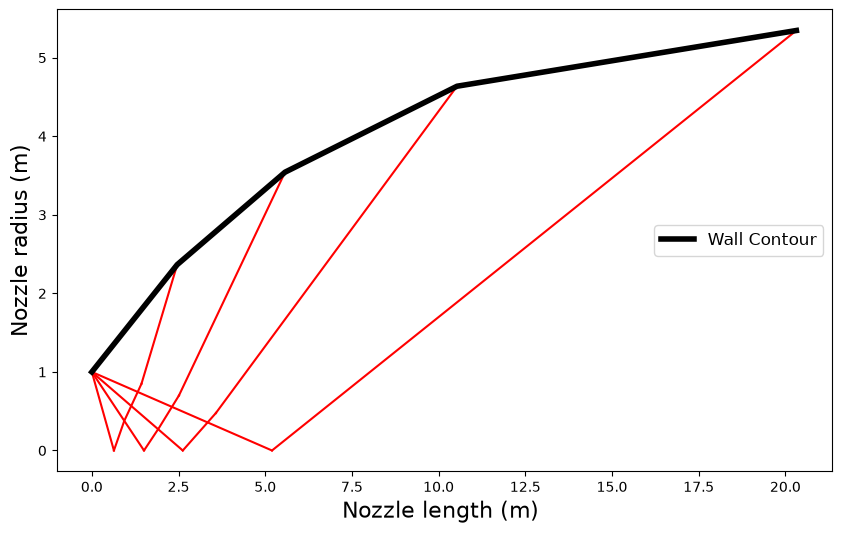

In [233]:
plt.figure(figsize=(10, 6))
for ray in rays:
    x = [p[6] for p in ray]
    y = [p[7] for p in ray]
    plt.plot([x[0], x_throat], [y[0], R_t], color = 'red')
    plt.plot(x[:-1], y[:-1], color = 'red')
    plt.plot(x[-2:], y[-2:], color = 'red')

wall_x = [x_throat] + [ray[-1][6] for ray in rays]
wall_y = [R_t] + [ray[-1][7] for ray in rays]
plt.plot(wall_x, wall_y, color='black', linewidth=4, label='Wall Contour')

plt.xlabel("Nozzle length (m) ", fontsize=16)
plt.ylabel("Nozzle radius (m)", fontsize=16)
plt.legend(loc=7, prop={'size': 12})
plt.show()

I looked at more than 2 codebase to understand how the 2D MOC nozzle works. 
No AI was used. All functions were written by me. 

https://github.com/nategphillips/moc/tree/main  
https://github.com/ekremekc/MoC
